# Feed Forward Net

- MNIST Dataset
- DataLoader, Transformation
- Multilayer Neural Net, Activation Function
- Loss and Optimizer
- Training Loop (Batch training)
- Model Evaluation
- GPU Support

## Importing Dependencies

In [1]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

## Device Config

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Define Hyperparameters

In [3]:
input_size = 784 # 28x28 images
hidden_size = 100
num_classes = 10
num_epochs = 10
batch_size = 100
learning_rate = 0.001

## Import and Prepare MNIST Dataset

In [5]:
train_dataset = torchvision.datasets.MNIST(root='./data', train=True, transform=transforms.ToTensor(), download=True)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, transform=transforms.ToTensor())

train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)

examples = iter(train_loader)
samples, labels = next(examples)
samples.shape, labels.shape

(torch.Size([100, 1, 28, 28]), torch.Size([100]))

## Visualizing the Sample Images

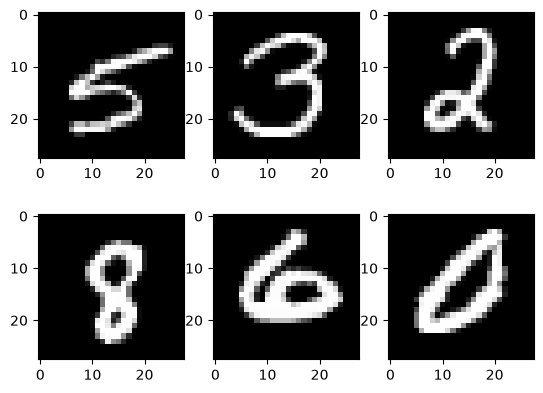

In [6]:
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(samples[i][0], cmap='gray')
plt.show()

## Neural Net Model

In [11]:
class NeuralNet(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super(NeuralNet, self).__init__()
        self.l1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.l2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        out = self.l1(x)
        out = self.relu(out)
        out = self.l2(out)
        return out

model = NeuralNet(input_size, hidden_size, num_classes).to(device)

## Loss and Optimizer

In [12]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

## Training Loop

In [13]:
n_total_steps = len(train_loader)

for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        # reshape from (100, 1, 28, 28) to (100, 784)
        images = images.reshape(-1, 28*28).to(device)
        labels = labels.to(device)

        # forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (i+1) % 100 == 0:
            print(f"Epoch {epoch+1}, Step {i+1}/{n_total_steps}: loss = {loss.item()} ")

Epoch 1, Step 100/600: loss = 0.38443267345428467 
Epoch 1, Step 200/600: loss = 0.2739039361476898 
Epoch 1, Step 300/600: loss = 0.5296101570129395 
Epoch 1, Step 400/600: loss = 0.359663188457489 
Epoch 1, Step 500/600: loss = 0.4706365466117859 
Epoch 1, Step 600/600: loss = 0.22938373684883118 
Epoch 2, Step 100/600: loss = 0.11817094683647156 
Epoch 2, Step 200/600: loss = 0.17531879246234894 
Epoch 2, Step 300/600: loss = 0.1753903329372406 
Epoch 2, Step 400/600: loss = 0.2825120687484741 
Epoch 2, Step 500/600: loss = 0.21301433444023132 
Epoch 2, Step 600/600: loss = 0.12740017473697662 
Epoch 3, Step 100/600: loss = 0.14819899201393127 
Epoch 3, Step 200/600: loss = 0.14922042191028595 
Epoch 3, Step 300/600: loss = 0.06246616318821907 
Epoch 3, Step 400/600: loss = 0.12712283432483673 
Epoch 3, Step 500/600: loss = 0.15231327712535858 
Epoch 3, Step 600/600: loss = 0.11746955662965775 
Epoch 4, Step 100/600: loss = 0.10739868134260178 
Epoch 4, Step 200/600: loss = 0.077896

## Testing & Evaluation

In [14]:
with torch.no_grad():
    n_correct = 0
    n_samples = 0
    for images, labels in test_loader:
        images = images.reshape(-1, 28*28).to(device)
        labels = labels.to(device)
        outputs = model(images)

        _, predictions = torch.max(outputs, 1)
        n_samples += labels.shape[0]
        n_correct = (predictions == labels).sum().item()

    acc = 100.0 * n_correct / n_samples

    print(f"Accuray: {acc}")

Accuray: 0.97
